# 05 From forecast error to inventory cost

Turns each method's forecast errors into overstock and stockout costs, then asks where LightGBM saves money over the best simple method (4-week average) and where it doesn't.

Inputs: `test_predictions.parquet` and `valid_predictions.parquet` (04_forecast). Outputs: CSV tables in `~/data/walmart-data/dashboard/` for Power BI, and one chart in `reports/figures/`.

**Method**
- Each week, the planner orders up to: forecast + safety stock.
- Safety stock = z × σ, where σ is the standard deviation of that method's errors for that series over the 13 validation weeks. A method that forecasts better gets less safety stock.
- z comes from the cost trade-off (newsvendor critical ratio): z = Φ⁻¹(stockout cost / (stockout cost + overstock cost)). When stockouts cost more than overstock, it pays to hold more.
- Overstock units = order minus actual sales, if positive. Stockout units = actual sales minus order, if positive.
- Cost = price × (overstock rate × overstock units + stockout rate × stockout units), summed over the 13 test weeks.

**Cost assumptions.** M5 has no cost or margin data. These are stated assumptions, not Walmart's costs, and the analysis is run under all four combinations:
- Overstock cost per unit per week (holding, markdown, spoilage): 5% (low) or 15% (high) of the item's price.
- Stockout cost per unit (lost margin and goodwill): 20% (low) or 50% (high) of the item's price.

**Measurable economic value (decided before running).** LightGBM's estimated savings over the 4-week average stay positive under all four cost scenarios.

## Kernel check

In [1]:
import sys, pandas, duckdb, pyarrow, scipy
print(sys.executable)
print(pandas.__version__, duckdb.__version__, pyarrow.__version__, scipy.__version__)

/Users/rajkandula/projects/walmart-demand-forecasting/.venv/bin/python
3.0.6 1.5.5 25.0.1 1.18.1


## Setup

In [2]:
import sys; sys.path.append("..")
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from src.config import PROCESSED_DIR, DASHBOARD_DIR

con = duckdb.connect()
test = pd.read_parquet(PROCESSED_DIR / "test_predictions.parquet")
valid = pd.read_parquet(PROCESSED_DIR / "valid_predictions.parquet")

best_simple = test.loc[test["is_best_simple"], "method"].iloc[0]
print(test.shape, valid.shape, "best simple:", best_simple)
assert test["id"].nunique() == 9_147

(475644, 14) (475584, 14) best simple: ma_4


## Safety stock inputs: error spread per series and method

σ comes from validation weeks only, so the test weeks stay unseen. Series with fewer than 2 validation weeks (launched late) have no σ; they get 0 safety stock, and the count is printed.

In [3]:
sigma = (
    valid.assign(err=valid["forecast"] - valid["sales"])
    .groupby(["id", "method"], observed=True)["err"]
    .std(ddof=1)
    .rename("sigma")
    .reset_index()
)
print("series-method pairs without sigma:", sigma["sigma"].isna().sum())
sigma["sigma"] = sigma["sigma"].fillna(0)

df = test.merge(sigma, on=["id", "method"], how="left")
df["sigma"] = df["sigma"].fillna(0)
assert len(df) == len(test)

series-method pairs without sigma: 0


## Price per row

The week's average shelf price, falling back to the 13-week average when the item wasn't priced that week. Rows with no price at all get 0, which means their errors carry no cost; the count is printed.

In [4]:
df["price"] = df["avg_price"].fillna(df["price_ma_13"])
print("rows without any price:", df["price"].isna().sum(), "of", len(df))
df["price"] = df["price"].fillna(0)

rows without any price: 0 of 475644


## Cost under each scenario

Order quantity is kept as a continuous expected value rather than rounded to whole units, which keeps the comparison between methods clean.

In [5]:
scenarios = pd.DataFrame(
    [("low_over_low_under", 0.05, 0.20),
     ("low_over_high_under", 0.05, 0.50),
     ("high_over_low_under", 0.15, 0.20),
     ("high_over_high_under", 0.15, 0.50)],
    columns=["scenario", "over_rate", "under_rate"],
)
scenarios["critical_ratio"] = scenarios["under_rate"] / (scenarios["under_rate"] + scenarios["over_rate"])
scenarios["z"] = norm.ppf(scenarios["critical_ratio"])
print(scenarios.round(3))

frames = []
for s in scenarios.itertuples():
    c = df.copy()
    order_qty = (c["forecast"] + s.z * c["sigma"]).clip(lower=0)
    c["scenario"] = s.scenario
    c["order_qty"] = order_qty
    c["over_units"] = (order_qty - c["sales"]).clip(lower=0)
    c["under_units"] = (c["sales"] - order_qty).clip(lower=0)
    c["over_cost"] = c["price"] * s.over_rate * c["over_units"]
    c["under_cost"] = c["price"] * s.under_rate * c["under_units"]
    c["total_cost"] = c["over_cost"] + c["under_cost"]
    frames.append(c)

cost = pd.concat(frames, ignore_index=True)
cost["abs_error"] = (cost["forecast"] - cost["sales"]).abs()
print(cost.shape)
assert len(cost) == 4 * len(df)

               scenario  over_rate  under_rate  critical_ratio      z
0    low_over_low_under       0.05         0.2           0.800  0.842
1   low_over_high_under       0.05         0.5           0.909  1.335
2   high_over_low_under       0.15         0.2           0.571  0.180
3  high_over_high_under       0.15         0.5           0.769  0.736
(1902576, 24)


## Total cost by method and scenario

13 test weeks, all three stores.

In [6]:
con.sql("""
SELECT scenario, method,
       ROUND(SUM(total_cost))::BIGINT AS total_cost,
       ROUND(SUM(over_cost))::BIGINT AS overstock_cost,
       ROUND(SUM(under_cost))::BIGINT AS stockout_cost,
       ROUND(SUM(under_units) / SUM(sales), 3) AS stockout_rate
FROM cost
GROUP BY ALL
ORDER BY scenario, total_cost
""").show(max_rows=20)

┌──────────────────────┬─────────┬────────────┬────────────────┬───────────────┬───────────────┐
│       scenario       │ method  │ total_cost │ overstock_cost │ stockout_cost │ stockout_rate │
│       varchar        │ varchar │   int64    │     int64      │     int64     │    double     │
├──────────────────────┼─────────┼────────────┼────────────────┼───────────────┼───────────────┤
│ high_over_high_under │ lgbm    │     337207 │         199171 │        138035 │         0.079 │
│ high_over_high_under │ ma_4    │     363520 │         223775 │        139745 │          0.08 │
│ high_over_high_under │ naive   │     393051 │         253475 │        139575 │         0.079 │
│ high_over_high_under │ ma_13   │     393834 │         219728 │        174106 │         0.102 │
│ high_over_low_under  │ lgbm    │     211303 │         108198 │        103105 │         0.147 │
│ high_over_low_under  │ ma_4    │     225734 │         121035 │        104699 │          0.15 │
│ high_over_low_under  │ ma_13

## Savings by segment: LightGBM vs the best simple method

`FILTER` pulls each method's cost into its own column in one pass. A segment passes the value test when savings are positive in all four scenarios.

In [7]:
savings_sql = """
WITH seg AS (
    SELECT scenario, {by},
           SUM(total_cost) FILTER (WHERE method = 'lgbm') AS lgbm_cost,
           SUM(total_cost) FILTER (WHERE method = '{best}') AS simple_cost
    FROM cost
    GROUP BY ALL
)
SELECT {by},
       ROUND(MIN(simple_cost - lgbm_cost))::BIGINT AS min_savings,
       ROUND(MAX(simple_cost - lgbm_cost))::BIGINT AS max_savings,
       ROUND(100 * MIN((simple_cost - lgbm_cost) / simple_cost), 1) AS min_pct,
       ROUND(100 * MAX((simple_cost - lgbm_cost) / simple_cost), 1) AS max_pct,
       BOOL_AND(simple_cost > lgbm_cost) AS passes_all_scenarios
FROM seg
GROUP BY ALL
ORDER BY ALL
"""
for by in ["'all' AS total", "pattern", "store_id", "cat_id", "dept_id"]:
    con.sql(savings_sql.format(by=by, best=best_simple)).show()

┌─────────┬─────────────┬─────────────┬─────────┬─────────┬──────────────────────┐
│  total  │ min_savings │ max_savings │ min_pct │ max_pct │ passes_all_scenarios │
│ varchar │    int64    │    int64    │ double  │ double  │       boolean        │
├─────────┼─────────────┼─────────────┼─────────┼─────────┼──────────────────────┤
│ all     │        9609 │       26313 │     6.4 │     7.4 │ true                 │
└─────────┴─────────────┴─────────────┴─────────┴─────────┴──────────────────────┘

┌────────────────────────────────────────────────────┬─────────────┬─────────────┬─────────┬─────────┬──────────────────────┐
│                      pattern                       │ min_savings │ max_savings │ min_pct │ max_pct │ passes_all_scenarios │
│ enum('erratic', 'intermittent', 'lumpy', 'smooth') │    int64    │    int64    │ double  │ double  │       boolean        │
├────────────────────────────────────────────────────┼─────────────┼─────────────┼─────────┼─────────┼─────────────────────

## Series level: how concentrated are the savings?

If a small share of series produces most of the savings, a planner could run the complex model only there and keep the simple method everywhere else.

In [8]:
con.sql(f"""
CREATE OR REPLACE TABLE series_savings AS
SELECT scenario, id, item_id, dept_id, cat_id, store_id, pattern,
       SUM(total_cost) FILTER (WHERE method = 'lgbm') AS lgbm_cost,
       SUM(total_cost) FILTER (WHERE method = '{best_simple}') AS simple_cost,
       SUM(total_cost) FILTER (WHERE method = '{best_simple}')
         - SUM(total_cost) FILTER (WHERE method = 'lgbm') AS savings
FROM cost
GROUP BY ALL
""")

# Share of series where LightGBM saves money in every scenario, by pattern
con.sql("""
WITH s AS (
    SELECT id, pattern, BOOL_AND(savings > 0) AS saves_everywhere
    FROM series_savings
    GROUP BY ALL
)
SELECT pattern, COUNT(*) AS n_series,
       ROUND(100.0 * AVG(saves_everywhere::INT), 1) AS pct_series_saving
FROM s
GROUP BY ALL
ORDER BY pattern
""").show()

# Concentration: share of net savings from the top 10% and 20% of series (ranked by savings)
con.sql("""
WITH ranked AS (
    SELECT scenario, savings,
           PERCENT_RANK() OVER (PARTITION BY scenario ORDER BY savings DESC) AS pr
    FROM series_savings
)
SELECT scenario,
       ROUND(SUM(savings))::BIGINT AS net_savings,
       ROUND(100 * SUM(savings) FILTER (WHERE pr < 0.10) / SUM(savings), 1) AS pct_from_top_10pct,
       ROUND(100 * SUM(savings) FILTER (WHERE pr < 0.20) / SUM(savings), 1) AS pct_from_top_20pct
FROM ranked
GROUP BY ALL
ORDER BY scenario
""").show()

# Average savings per series by pattern (13 weeks)
con.sql("""
SELECT pattern, scenario, COUNT(*) AS n_series,
       ROUND(AVG(savings), 2) AS avg_savings_per_series,
       ROUND(SUM(savings))::BIGINT AS total_savings
FROM series_savings
GROUP BY ALL
ORDER BY pattern, scenario
""").show(max_rows=20)

┌────────────────────────────────────────────────────┬──────────┬───────────────────┐
│                      pattern                       │ n_series │ pct_series_saving │
│ enum('erratic', 'intermittent', 'lumpy', 'smooth') │  int64   │      double       │
├────────────────────────────────────────────────────┼──────────┼───────────────────┤
│ erratic                                            │      699 │              39.3 │
│ intermittent                                       │     3104 │              43.1 │
│ lumpy                                              │      942 │              40.2 │
│ smooth                                             │     4402 │              43.4 │
└────────────────────────────────────────────────────┴──────────┴───────────────────┘

┌──────────────────────┬─────────────┬────────────────────┬────────────────────┐
│       scenario       │ net_savings │ pct_from_top_10pct │ pct_from_top_20pct │
│       varchar        │    int64    │       double       │    

## Chart for the README

Percent cost savings by demand pattern, low-cost and high-cost scenarios.

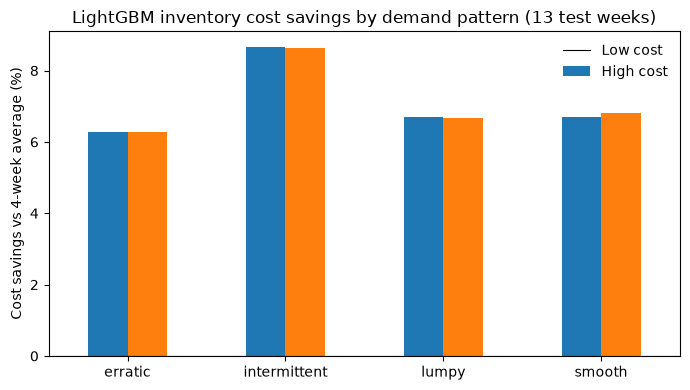

In [9]:
plot_df = con.sql(f"""
SELECT pattern, scenario,
       100 * (SUM(total_cost) FILTER (WHERE method = '{best_simple}')
            - SUM(total_cost) FILTER (WHERE method = 'lgbm'))
           / SUM(total_cost) FILTER (WHERE method = '{best_simple}') AS pct_savings
FROM cost
WHERE scenario IN ('low_over_low_under', 'high_over_high_under')
GROUP BY ALL
ORDER BY pattern
""").df()

wide = plot_df.pivot(index="pattern", columns="scenario", values="pct_savings")
ax = wide.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_ylabel("Cost savings vs 4-week average (%)")
ax.set_xlabel("")
ax.set_title("LightGBM inventory cost savings by demand pattern (13 test weeks)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(["Low cost", "High cost"], frameon=False)
plt.tight_layout()

fig_dir = Path("..") / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_dir / "savings_by_pattern.png", dpi=150)
plt.show()

## Export tables for Power BI

Small, pre-aggregated CSVs so the dashboard stays fast. Power BI rebuilds every visual from these.

In [10]:
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)

segment_costs = con.sql("""
SELECT scenario, store_id, cat_id, dept_id, pattern, method,
       SUM(sales) AS units, SUM(forecast) AS forecast_units,
       SUM(abs_error) AS abs_error,
       SUM(over_units) AS over_units, SUM(under_units) AS under_units,
       SUM(over_cost) AS over_cost, SUM(under_cost) AS under_cost,
       SUM(total_cost) AS total_cost
FROM cost
GROUP BY ALL
""").df()

weekly_trend = con.sql("""
SELECT week_num, wm_yr_wk, store_id, cat_id, method,
       SUM(sales) AS units, SUM(forecast) AS forecast_units
FROM test
GROUP BY ALL
ORDER BY week_num
""").df()

series_sav = con.sql("SELECT * FROM series_savings").df()
profile = pd.read_parquet(PROCESSED_DIR / "series_profile.parquet")

outputs = {
    "segment_costs.csv": segment_costs,
    "weekly_trend.csv": weekly_trend,
    "series_savings.csv": series_sav,
    "series_profile.csv": profile,
    "scenarios.csv": scenarios,
}
for name, table in outputs.items():
    table.to_csv(DASHBOARD_DIR / name, index=False)
    print(name, table.shape, round((DASHBOARD_DIR / name).stat().st_size / 1e6, 2), "MB")

segment_costs.csv (1344, 14) 0.24 MB
weekly_trend.csv (468, 7) 0.02 MB
series_savings.csv (36588, 10) 5.51 MB
series_profile.csv (9147, 14) 1.64 MB
scenarios.csv (4, 5) 0.0 MB


## Results

All dollar figures cover the 13 test weeks across the three Texas stores and rest on the stated cost assumptions, not Walmart's real costs.

**Total cost by scenario (LightGBM vs 4-week average):**

| Scenario (overstock / stockout rate) | 4-week avg | LightGBM | Savings | % |
|---|---|---|---|---|
| 5% / 20% | $131,715 | $122,106 | $9,609 | 7.3% |
| 5% / 50% | $193,635 | $179,308 | $14,327 | 7.4% |
| 15% / 20% | $225,734 | $211,303 | $14,432 | 6.4% |
| 15% / 50% | $363,520 | $337,207 | $26,313 | 7.2% |

LightGBM passes the value test: savings stay positive in all four scenarios, 6.4% to 7.4%. The 13-week average and naive methods cost more than the 4-week average in every scenario.

**Where the savings come from.** About 93% of the savings are lower overstock cost, not fewer stockouts. In the 15% / 50% scenario, overstock cost falls by $24,604 and stockout cost by $1,710. LightGBM's errors are tighter, so it needs less safety stock to hold the same service level (stockout rate 7.9% vs 8.0%). Its 1.8% under-forecasting bias from 04 didn't raise stockouts.

**By segment (savings range across the four scenarios):**

| Segment | Savings | % |
|---|---|---|
| Smooth | $5,073 to $13,827 | 5.8 to 6.8 |
| Intermittent | $3,308 to $9,125 | 7.9 to 9.1 |
| Erratic | $643 to $1,754 | 5.1 to 6.3 |
| Lumpy | $586 to $1,607 | 6.3 to 7.1 |
| FOODS | $6,286 to $17,039 | 8.0 to 10.1 |
| HOUSEHOLD | $2,296 to $6,401 | 4.3 to 5.1 |
| HOBBIES | $1,027 to $2,874 | 4.6 to 5.1 |
| FOODS_3 (best department) | $4,120 to $11,048 | 8.2 to 11.8 |
| HOBBIES_2 (weakest department) | $13 to $140 | 0.4 to 2.5 |

Every pattern, store, category, and department passes. Smooth series produce about 53% of the dollar savings because they carry most of the volume. Intermittent series have the highest percentage savings, which goes against the expectation that a complex model adds little on sparse demand. HOBBIES_2 technically passes but saves $13 to $140 in 13 weeks, which is not worth separate attention.

**Series level, which is where the real answer is:**
- LightGBM saves money in all four scenarios for only 42.7% of series (39.3% to 43.4% by pattern). For the rest it's a wash or slightly worse.
- The top 10% of series by savings produce 90% to 107% of net savings. The top 20% produce more than 100%, meaning the other 80% net to zero or slightly negative.
- Average savings per series are small: $0.62 to $3.14 per 13 weeks, depending on pattern and scenario.

**Answer to the business question.** Better forecasting pays off, but not evenly. Aggregate savings are a steady 6% to 7% under every cost assumption, led by FOODS (especially FOODS_3) and by smooth series in dollar terms. The value sits in a small set of series: about one in ten items produces nearly all of it. For a demand planning manager, the move is to focus review and exception effort on those high-savings series and FOODS_3, and treat the 4-week average as sufficient for low-value areas like HOBBIES_2. Because LightGBM runs as one global model, the extra cost of scoring every series is small; the effort to manage is analyst attention, not compute.

**Limits.** Costs are assumptions expressed as shares of each item's price. Order quantities are continuous, not rounded to case packs. There are no lead times or shelf-capacity limits. The test covers 13 weeks only. LightGBM's safety stock uses validation errors from the same weeks used for early stopping, which slightly understates its safety stock and works against it.
